In [2]:
!pip -q install imagehash

# Classificação de imagens com CNN treinada do zero — Intel Image Classification

**Aluno:** Guilherme Grigolin da Mata Brandão
**Curso:** Bacharelado em Sistemas de Informação — IFSP
**Projeto prático de CNNs**

## Objetivo
Construir e analisar uma rede neural convolucional (CNN), treinada do zero (pesos inicializados aleatoriamente),
para classificar cenas em seis categorias (*buildings, forest, glacier, mountain, sea, street*), avaliando como
taxa de aprendizado, capacidade da rede e regularização afetam o aprendizado e a generalização.

## Notebook de referência
- **Título:** *Intel Image Classification (CNN - Keras)*
- **Autor:** Vincenzooo (usuário Kaggle `vincee`)
- **Link:** https://www.kaggle.com/code/vincee/intel-image-classification-cnn-keras
- **Data de acesso:** 27/10/2026

**Ideias aproveitadas:** uso do conjunto oficial `seg_test` como teste, normalização dos pixels para [0, 1],
CNN Keras com blocos `Conv2D + ReLU + MaxPooling`, saída *softmax* com 6 neurônios, perda
`sparse_categorical_crossentropy`, otimizador Adam, curvas de treino/validação, matriz de confusão e
visualização de imagens classificadas incorretamente.

**Adaptações feitas:** (1) a referência usa `validation_split=0.2` sem estratificação e sem controle de
duplicatas; aqui a validação é estratificada e agrupada por duplicatas, com semente fixa e listas de arquivos
salvas; (2) a referência usa `Flatten` em 150×150; aqui são usadas imagens 128×128, três blocos com 32/64/128
filtros e `GlobalAveragePooling` (proposta do enunciado, muito menos parâmetros); (3) foram adicionados
EarlyStopping, checkpoint do melhor modelo, F1 macro e oito experimentos controlados; (4) a parte de
transferência de aprendizado (VGG16) da referência **não** foi usada, pois o projeto exige treino do zero.
Também foi consultado o notebook-base da disciplina (`notebook_base_aula.ipynb`), do qual vieram a leitura
com `kagglehub` e a localização das pastas.

## Como reproduzir
1. Python 3.10+ com as dependências da célula de instalação (fora do Colab/Kaggle, descomente o `pip install` da seção 1) (`tensorflow`, `kagglehub`, `scikit-learn`,
   `pandas`, `matplotlib`, `pillow`, `imagehash`).
2. A base é baixada automaticamente com `kagglehub.dataset_download("puneet6060/intel-image-classification")`
   (não exige login para esta base pública). No Kaggle/Colab o cache local é usado.
3. Execute todas as células em sequência (*Run all*). Os artefatos são gravados em `resultados/`:
   listas de arquivos de cada divisão, tabela de experimentos em CSV, históricos, pesos e figuras.
4. Esta execução foi feita no **Google Colab com GPU** (runtime T4 selecionado; o código registra apenas `GPU:0`): cerca de 4 min por experimento sem aumento de dados e
   ~16 min com aumento (as transformações rodam na CPU). Em CPU pura a execução completa leva algumas horas.
5. No Colab, a última célula compacta `resultados/` em `resultados.zip` para download. Os pesos (`resultados/modelos/`)
   não foram versionados no repositório (o ambiente do Colab foi reiniciado antes do download); os demais artefatos
   (tabela de resultados, históricos, métricas e figuras) foram extraídos das saídas deste notebook; as listas de
   arquivos de cada divisão foram regeneradas com o mesmo código, semente e versões (contagens por classe e imagens
   de exemplo conferidas como idênticas).

## Uso de ferramentas de IA
Foi utilizado o assistente **Claude (Anthropic) via Claude Code** como apoio na escrita do código, na organização
dos experimentos e na redação do texto. Todos os resultados numéricos e gráficos foram produzidos pela execução
real deste notebook.

## 1. Ambiente, versões e semente

In [3]:
# Instalação das dependências (descomente se necessário)
# !pip -q install tensorflow kagglehub scikit-learn pandas matplotlib pillow imagehash

In [4]:
import os, sys, json, time, platform, hashlib, random
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import PIL
import imagehash
import kagglehub
import tensorflow as tf
from pathlib import Path
from PIL import Image
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (f1_score, accuracy_score, classification_report,
                             confusion_matrix, precision_recall_fscore_support)

SEED = 42
def fixar_semente(seed=SEED):
    # Python, NumPy e TensorFlow usam a mesma semente
    tf.keras.utils.set_random_seed(seed)

fixar_semente()

PASTA_SAIDA = Path("resultados")
PASTA_FIG = PASTA_SAIDA / "figuras"
PASTA_MOD = PASTA_SAIDA / "modelos"
PASTA_HIST = PASTA_SAIDA / "historicos"
for p in (PASTA_SAIDA, PASTA_FIG, PASTA_MOD, PASTA_HIST):
    p.mkdir(parents=True, exist_ok=True)

def info_cpu():
    try:
        for linha in open("/proc/cpuinfo"):
            if linha.startswith("model name"):
                return linha.split(":", 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or "desconhecido"

def info_ram_gb():
    try:
        return round(os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1024**3, 1)
    except (ValueError, OSError, AttributeError):
        return None

ambiente = {
    "python": sys.version.split()[0],
    "tensorflow": tf.__version__,
    "keras": keras.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "pillow": PIL.__version__,
    "imagehash": imagehash.__version__,
    "sistema": platform.platform(),
    "cpu": info_cpu(),
    "nucleos_cpu": os.cpu_count(),
    "ram_gb": info_ram_gb(),
    "gpus": [g.name for g in tf.config.list_physical_devices("GPU")] or "nenhuma (treino em CPU)",
    "semente": SEED,
}
json.dump(ambiente, open(PASTA_SAIDA / "ambiente.json", "w"), indent=2, ensure_ascii=False)
pd.Series(ambiente, name="valor").to_frame()

,valor
python,3.13.16
tensorflow,2.21.0
keras,3.13.2
numpy,2.1.3
pandas,2.2.3
scikit-learn,1.6.1
matplotlib,3.10.0
pillow,11.3.0
imagehash,4.3.2
sistema,Linux-6.6.159+-x86_64-with-glibc2.39


## 2. Download da base e localização das pastas

In [5]:
caminho = Path(kagglehub.dataset_download("puneet6060/intel-image-classification"))
print("Dados em:", caminho)

classes = ["buildings", "forest", "glacier", "mountain", "sea", "street"]
classe_para_indice = {c: i for i, c in enumerate(classes)}

def localizar_pasta(nome):
    for pasta in [caminho / nome] + list(caminho.rglob(nome)):
        if pasta.is_dir() and all((pasta / c).is_dir() for c in classes):
            return pasta
    raise FileNotFoundError(f"Pasta {nome} com as seis classes não encontrada.")

pasta_treino = localizar_pasta("seg_train")
pasta_teste = localizar_pasta("seg_test")
print("Treino oficial:", pasta_treino)
print("Teste oficial :", pasta_teste)
print("Pastas no topo da base:", sorted(p.name for p in caminho.iterdir()))
print("Mapeamento:", classe_para_indice)

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Dados em: /kaggle/input/intel-image-classification
Treino oficial: /kaggle/input/intel-image-classification/seg_train/seg_train
Teste oficial : /kaggle/input/intel-image-classification/seg_test/seg_test
Pastas no topo da base: ['seg_pred', 'seg_test', 'seg_train']
Mapeamento: {'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}


A versão baixada contém `seg_train` (treino rotulado), `seg_test` (teste rotulado) e `seg_pred`
(imagens **sem rótulo**). `seg_pred` não é usada, pois não permite calcular acurácia nem F1.

## 3. Inspeção dos dados: arquivos corrompidos, tamanhos e duplicatas

Procedimento:
1. Cada arquivo é aberto e decodificado por completo com Pillow; falhas são registradas como corrompidas.
2. Calcula-se o MD5 dos bytes (duplicata exata) e o *perceptual hash* (pHash, 64 bits) de cada imagem.
3. Dois arquivos são considerados **a mesma imagem** se tiverem o mesmo MD5 ou distância de Hamming
   entre pHashes ≤ 6. O limiar foi escolhido por inspeção visual: até 6 os pares eram a mesma foto
   (recortes/reamostragens); a partir de 8 já surgiam cenas diferentes.
4. Os pares formam **grupos** (union-find). Regras: (a) grupo com membros no treino e no teste → os membros do
   treino são excluídos (o teste oficial é preservado); (b) grupo do treino com rótulos conflitantes → excluído
   (rótulo ambíguo); (c) os demais grupos ficam inteiros no mesmo conjunto na divisão treino/validação.

In [6]:
def listar(pasta, origem):
    registros = []
    for classe in classes:
        for arq in sorted((pasta / classe).iterdir()):
            if arq.suffix.lower() in {".jpg", ".jpeg", ".png"}:
                registros.append({"caminho": str(arq), "arquivo": f"{origem}/{classe}/{arq.name}",
                                  "origem": origem, "classe": classe, "rotulo": classe_para_indice[classe]})
    return registros

tabela = pd.DataFrame(listar(pasta_treino, "seg_train") + listar(pasta_teste, "seg_test"))

md5s, phashes, larguras, alturas, corrompidos = [], [], [], [], []
for cam in tabela["caminho"]:
    try:
        dados = Path(cam).read_bytes()
        with Image.open(cam) as im:
            im.load()
            im = im.convert("RGB")
            larguras.append(im.width); alturas.append(im.height)
            phashes.append(int(str(imagehash.phash(im)), 16))
        md5s.append(hashlib.md5(dados).hexdigest())
        corrompidos.append(False)
    except Exception as e:
        md5s.append(None); phashes.append(0); larguras.append(None); alturas.append(None)
        corrompidos.append(True)

tabela["md5"], tabela["phash"] = md5s, phashes
tabela["largura"], tabela["altura"], tabela["corrompido"] = larguras, alturas, corrompidos

print("Total de arquivos rotulados:", len(tabela))
print("Arquivos corrompidos:", int(tabela["corrompido"].sum()))
print("\nTamanhos mais comuns (largura x altura):")
print((tabela["largura"].astype(str) + "x" + tabela["altura"].astype(str)).value_counts().head(6).to_string())

Total de arquivos rotulados: 17034
Arquivos corrompidos: 0

Tamanhos mais comuns (largura x altura):
150x150    16979
150x113        7
150x135        3
150x111        3
150x136        2
150x143        2


In [7]:
# Agrupamento de duplicatas: MD5 igual OU distância de Hamming entre pHashes <= LIMIAR
LIMIAR_PHASH = 6
validos = tabela[~tabela["corrompido"]].reset_index(drop=True)
n = len(validos)
pai = list(range(n))
def achar(i):
    while pai[i] != i:
        pai[i] = pai[pai[i]]; i = pai[i]
    return i
def unir(a, b):
    ra, rb = achar(a), achar(b)
    if ra != rb: pai[rb] = ra

for _, idx in validos.groupby("md5").groups.items():
    idx = list(idx)
    for j in idx[1:]: unir(idx[0], j)

H = validos["phash"].to_numpy(dtype=np.uint64)
pares_phash = 0
for ini in range(0, n, 1000):
    x = H[ini:ini + 1000, None] ^ H[None, :]
    dist = np.unpackbits(x.view(np.uint8).reshape(x.shape + (8,)), axis=-1).sum(-1)
    ii, jj = np.nonzero(dist <= LIMIAR_PHASH)
    for a, b in zip(ii + ini, jj):
        if b > a:
            unir(int(a), int(b)); pares_phash += 1

validos["grupo"] = [achar(i) for i in range(n)]
tam_grupo = validos.groupby("grupo")["arquivo"].transform("size")
dup = validos[tam_grupo > 1]
print("Pares semelhantes encontrados (pHash):", pares_phash)
print("Grupos com mais de uma imagem:", dup["grupo"].nunique(), "| imagens envolvidas:", len(dup))

Pares semelhantes encontrados (pHash): 143
Grupos com mais de uma imagem: 96 | imagens envolvidas: 209


In [8]:
# Aplicação das regras de exclusão
origens = validos.groupby("grupo")["origem"].agg(set)
classes_no_treino = validos[validos["origem"] == "seg_train"].groupby("grupo")["classe"].agg(set)

motivo = pd.Series("", index=validos.index)
cruza = validos["grupo"].map(lambda g: {"seg_train", "seg_test"} <= origens[g])
motivo[cruza & (validos["origem"] == "seg_train")] = "duplicata de imagem do teste"
conflito = validos["grupo"].map(lambda g: len(classes_no_treino.get(g, set())) > 1)
motivo[(motivo == "") & conflito & (validos["origem"] == "seg_train")] = "duplicata com rótulos conflitantes"

exclusoes = pd.concat([
    tabela[tabela["corrompido"]].assign(motivo="arquivo corrompido"),
    validos[motivo != ""].assign(motivo=motivo[motivo != ""]),
])
exclusoes[["arquivo", "origem", "classe", "motivo"]].to_csv(PASTA_SAIDA / "exclusoes.csv", index=False)
print("Exclusões por motivo:")
print(exclusoes["motivo"].value_counts().to_string())

conflito_teste = validos[validos["origem"] == "seg_test"].groupby("grupo")["classe"].nunique()
print("\nGrupos do teste com rótulos conflitantes (mantidos, pois o teste oficial é preservado):",
      int((conflito_teste > 1).sum()))

limpos = validos[motivo == ""].reset_index(drop=True)

Exclusões por motivo:
motivo
duplicata de imagem do teste          42
duplicata com rótulos conflitantes    20

Grupos do teste com rótulos conflitantes (mantidos, pois o teste oficial é preservado): 0


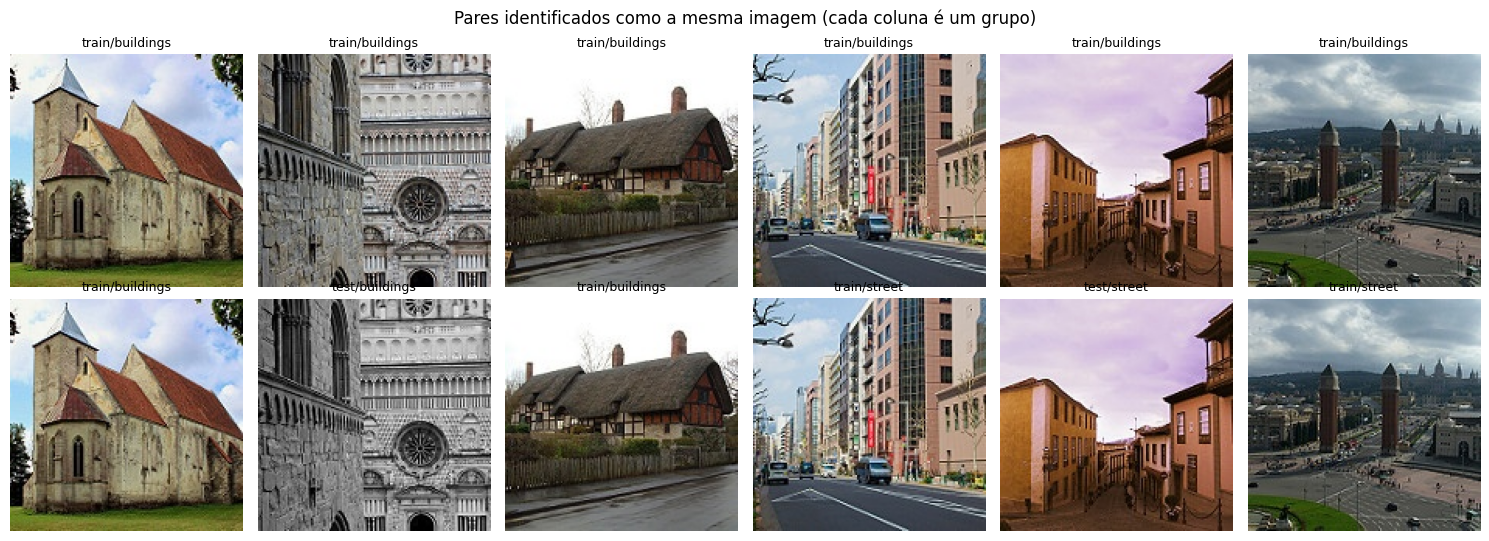

In [9]:
# Exemplos de pares agrupados como a mesma imagem
grupos_ex = dup.groupby("grupo").filter(lambda g: len(g) >= 2)["grupo"].unique()[:6]
fig, eixos = plt.subplots(2, 6, figsize=(15, 5.5))
for k, g in enumerate(grupos_ex):
    membros = validos[validos["grupo"] == g].head(2)
    for j, (_, r) in enumerate(membros.iterrows()):
        eixos[j, k].imshow(Image.open(r["caminho"])); eixos[j, k].axis("off")
        eixos[j, k].set_title(f"{r['origem'][4:]}/{r['classe']}", fontsize=9)
plt.suptitle("Pares identificados como a mesma imagem (cada coluna é um grupo)")
plt.tight_layout(); plt.savefig(PASTA_FIG / "duplicatas.png", dpi=110); plt.show()

## 4. Divisão treino / validação / teste

A base tem divisão oficial de treino e teste. O teste oficial (`seg_test`) é preservado e ~20% do treino é
separado para validação com `StratifiedGroupKFold` (5 dobras, usa-se a primeira): estratificado por classe e
**agrupado por duplicata**, de modo que versões da mesma imagem fiquem no mesmo conjunto. A semente é fixa e as
listas de arquivos de cada conjunto são salvas em CSV; todos os experimentos usam exatamente esta divisão.

In [10]:
treino_completo = limpos[limpos["origem"] == "seg_train"].reset_index(drop=True)
dados_teste = limpos[limpos["origem"] == "seg_test"].reset_index(drop=True)

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
idx_tr, idx_va = next(sgkf.split(treino_completo, treino_completo["rotulo"], treino_completo["grupo"]))
dados_treino = treino_completo.iloc[idx_tr].reset_index(drop=True)
dados_validacao = treino_completo.iloc[idx_va].reset_index(drop=True)

# Verificações de vazamento
assert not set(dados_treino["grupo"]) & set(dados_validacao["grupo"])
assert not set(dados_treino["grupo"]) & set(dados_teste["grupo"])
assert not set(dados_validacao["grupo"]) & set(dados_teste["grupo"])

colunas = ["arquivo", "classe", "rotulo", "grupo"]
dados_treino[colunas].to_csv(PASTA_SAIDA / "split_treino.csv", index=False)
dados_validacao[colunas].to_csv(PASTA_SAIDA / "split_validacao.csv", index=False)
dados_teste[colunas].to_csv(PASTA_SAIDA / "split_teste.csv", index=False)

distribuicao = pd.DataFrame({
    "Treino": dados_treino["classe"].value_counts(),
    "Validação": dados_validacao["classe"].value_counts(),
    "Teste": dados_teste["classe"].value_counts(),
}).reindex(classes)
distribuicao.loc["TOTAL"] = distribuicao.sum()
distribuicao["% validação/(treino+val)"] = (100 * distribuicao["Validação"] /
                                           (distribuicao["Treino"] + distribuicao["Validação"])).round(1)
distribuicao.to_csv(PASTA_SAIDA / "distribuicao_classes.csv")
distribuicao

,Treino,Validação,Teste,% validação/(treino+val)
classe,,,,
buildings,1747,438,437,20.0
forest,1806,451,474,20.0
glacier,1904,476,553,20.0
mountain,2004,498,525,19.9
sea,1816,455,510,20.0
street,1903,474,501,19.9
TOTAL,11180,2792,3000,20.0


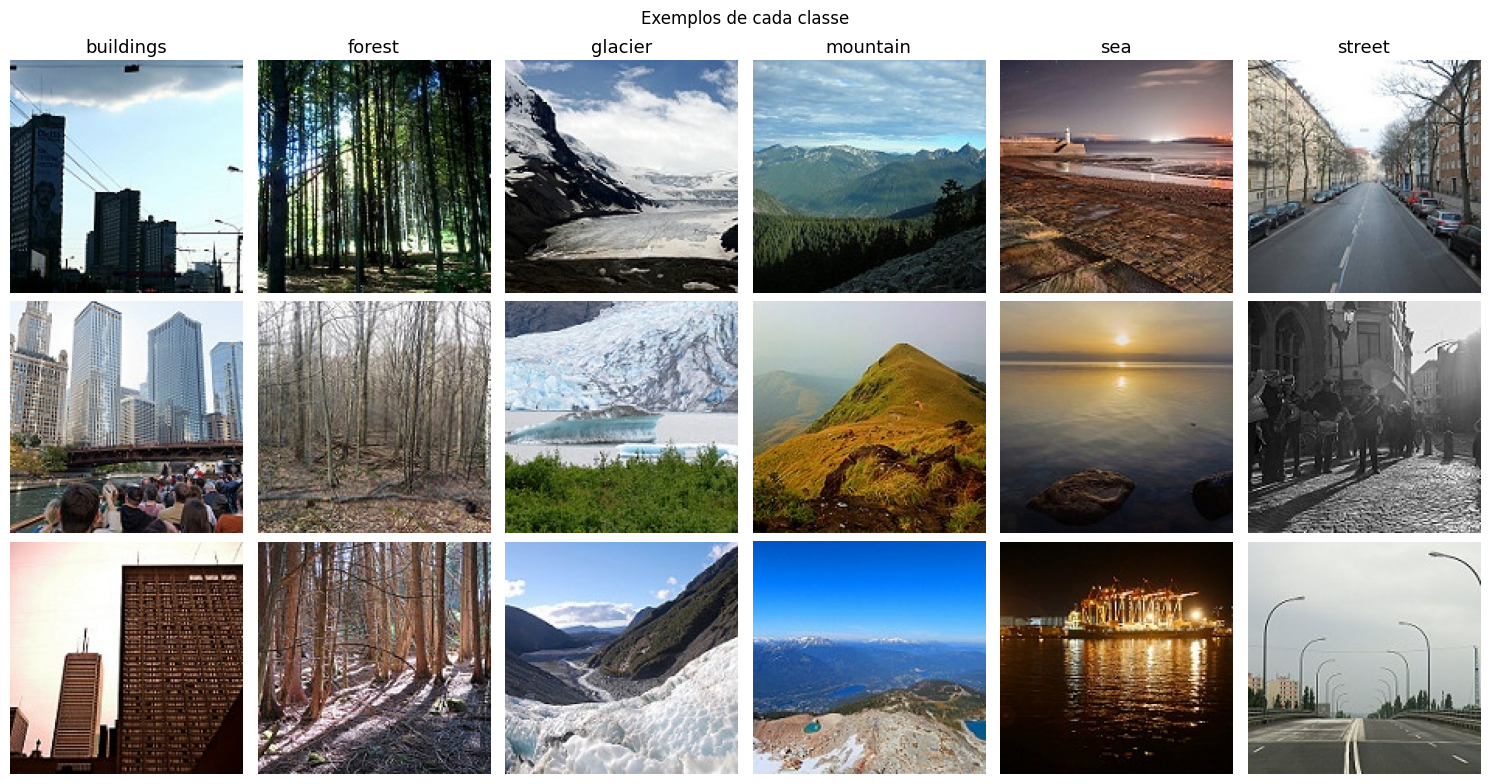

In [11]:
# Exemplos das seis classes (do conjunto de treino)
fig, eixos = plt.subplots(3, 6, figsize=(15, 8))
rng = np.random.default_rng(SEED)
for j, classe in enumerate(classes):
    amostra = dados_treino[dados_treino["classe"] == classe].sample(3, random_state=SEED)
    for i, cam in enumerate(amostra["caminho"]):
        eixos[i, j].imshow(Image.open(cam)); eixos[i, j].axis("off")
        if i == 0: eixos[i, j].set_title(classe, fontsize=13)
plt.suptitle("Exemplos de cada classe")
plt.tight_layout(); plt.savefig(PASTA_FIG / "exemplos_classes.png", dpi=110); plt.show()

## 5. Pré-processamento e pipeline de dados

- Todas as imagens são redimensionadas para **128×128×3** (interpolação bilinear) — quase todas são 150×150 e
  algumas têm altura menor, então o redimensionamento padroniza a entrada.
- Pixels são **normalizados** para [0, 1] (divisão por 255) dentro do pipeline `tf.data`.
- Para acelerar o treino, as imagens redimensionadas são mantidas em memória como `uint8`.
- O **aumento de dados** (quando usado) é aplicado **somente ao treino**, depois da divisão, e apenas durante
  o `fit`. Avaliações (inclusive no treino) usam as imagens sem aumento.

In [12]:
TAMANHO = (128, 128)
BATCH_SIZE = 32

def carregar_array(tab):
    X = np.empty((len(tab), *TAMANHO, 3), dtype=np.uint8)
    for i, cam in enumerate(tab["caminho"]):
        with Image.open(cam) as im:
            X[i] = np.asarray(im.convert("RGB").resize(TAMANHO, Image.BILINEAR))
    return X, tab["rotulo"].to_numpy(dtype="int32")

t0 = time.perf_counter()
X_tr, y_tr = carregar_array(dados_treino)
X_va, y_va = carregar_array(dados_validacao)
X_te, y_te = carregar_array(dados_teste)
print(f"Carregado em {time.perf_counter() - t0:.1f}s:", X_tr.shape, X_va.shape, X_te.shape)

aumento = keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.03, seed=SEED),   # até ±~11 graus
    layers.RandomZoom(0.10, seed=SEED),       # zoom de até ±10%
], name="aumento_de_dados")

def normalizar(x, y):
    return tf.cast(x, tf.float32) / 255.0, y

def criar_dataset(X, y, treino=False, aumentar=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if treino:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE).map(normalizar, num_parallel_calls=tf.data.AUTOTUNE)
    if aumentar:
        ds = ds.map(lambda x, y: (aumento(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

ds_tr_eval = criar_dataset(X_tr, y_tr)   # treino sem embaralhar/aumentar, só para avaliação
ds_va = criar_dataset(X_va, y_va)
ds_te = criar_dataset(X_te, y_te)

for xb, yb in criar_dataset(X_tr, y_tr, treino=True).take(1):
    print("Lote de imagens:", xb.shape, xb.dtype, "| min/max:", float(tf.reduce_min(xb)), float(tf.reduce_max(xb)))
    print("Lote de rótulos:", yb.shape, yb.numpy()[:12])

Carregado em 22.8s: (11180, 128, 128, 3) (2792, 128, 128, 3) (3000, 128, 128, 3)
Lote de imagens: (32, 128, 128, 3) <dtype: 'float32'> | min/max: 0.0 1.0
Lote de rótulos: (32,) [0 0 3 3 3 2 5 0 0 2 3 2]


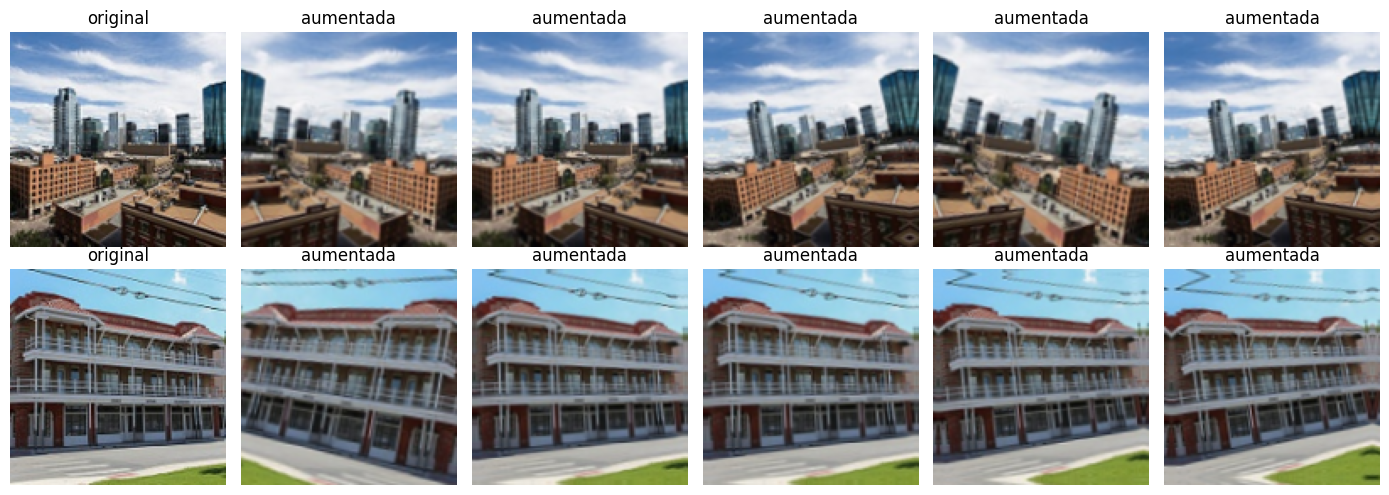

In [13]:
# Visualização do aumento de dados (apenas ilustração)
xb, yb = next(iter(criar_dataset(X_tr[:8], y_tr[:8])))
fig, eixos = plt.subplots(2, 6, figsize=(14, 5))
for i in range(2):
    eixos[i, 0].imshow(xb[i]); eixos[i, 0].set_title("original"); eixos[i, 0].axis("off")
    for j in range(1, 6):
        eixos[i, j].imshow(aumento(xb[i:i+1], training=True)[0]); eixos[i, j].set_title("aumentada"); eixos[i, j].axis("off")
plt.tight_layout(); plt.savefig(PASTA_FIG / "aumento_dados.png", dpi=100); plt.show()

## 6. CNN inicial (E0)

Arquitetura (pesos aleatórios — inicialização Glorot uniforme padrão do Keras, sem pesos pré-treinados):

| Camada | Saída | Função |
|---|---|---|
| Entrada RGB | 128×128×3 | imagem normalizada |
| Conv2D 32 filtros 3×3, ReLU, `same` | 128×128×32 | detecta padrões locais (bordas, cores) |
| MaxPooling 2×2 | 64×64×32 | reduz resolução, dá invariância a pequenos deslocamentos |
| Conv2D 64, ReLU + MaxPooling | 32×32×64 | combina padrões em texturas |
| Conv2D 128, ReLU + MaxPooling | 16×16×128 | partes/estruturas de cena mais abstratas |
| GlobalAveragePooling2D | 128 | média de cada mapa de ativação → vetor de características |
| Dense 128, ReLU | 128 | combina as características |
| Dense 6, softmax | 6 | probabilidade de cada classe (somam 1) |

Os rótulos são inteiros 0–5, então a perda compatível com a saída *softmax* é a
**`sparse_categorical_crossentropy`**, `-log(p_classe_verdadeira)`. A classe prevista é o `argmax` das seis
probabilidades. Otimizador **Adam** (lr = 0,001), *batch size* 32, até 30 épocas.

A função `construir_cnn` recebe os fatores investigados (número de blocos/filtros, Dropout, L2), para que cada
experimento altere somente um fator em relação ao E0.

In [14]:
def construir_cnn(filtros=(32, 64, 128), unidades_densas=128, dropout=0.0, l2=0.0, nome="cnn"):
    reg = regularizers.l2(l2) if l2 > 0 else None
    modelo = keras.Sequential(name=nome)
    modelo.add(keras.Input(shape=(*TAMANHO, 3)))
    for f in filtros:
        modelo.add(layers.Conv2D(f, 3, padding="same", activation="relu", kernel_regularizer=reg))
        modelo.add(layers.MaxPooling2D())
    modelo.add(layers.GlobalAveragePooling2D())
    modelo.add(layers.Dense(unidades_densas, activation="relu", kernel_regularizer=reg))
    if dropout > 0:
        modelo.add(layers.Dropout(dropout))           # posição: antes da camada de saída
    modelo.add(layers.Dense(len(classes), activation="softmax"))
    return modelo

fixar_semente()
m = construir_cnn(nome="E0_modelo_inicial")
m.summary()
print("Parâmetros treináveis:", m.count_params())
del m

Model: "E0_modelo_inicial"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,534 (431.77 KB)

 Trainable params: 110,534 (431.77 KB)

 Non-trainable params: 0 (0.00 B)

Parâmetros treináveis: 110534


## 7. Protocolo de treinamento e registro

- Cada experimento **reinicializa** a semente e constrói um modelo novo (nenhum peso é reaproveitado).
- `EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)`, limite de **30 épocas** — igual
  para todos os experimentos.
- `ModelCheckpoint` salva os pesos da época de menor `val_loss` em `resultados/modelos/<ID>.weights.h5`; esse
  arquivo é recarregado e é o **checkpoint usado na avaliação**.
- Após recarregar os melhores pesos, são calculadas no **treino (sem aumento) e na validação**: acurácia, perda
  e F1 macro. O histórico original (por época) é salvo em `resultados/historicos/<ID>.csv`.
- **Perda e L2:** no Keras, `loss`/`val_loss` incluem a penalidade L2 quando ela existe. Por isso a tabela traz
  `perda_total` (com L2, a que o Keras otimiza) e `perda_ce` (entropia cruzada pura, calculada a partir das
  probabilidades), que é a comparável entre experimentos.
- O conjunto de **teste não é usado** nesta etapa.

In [15]:
EPOCAS_MAX = 30
PACIENCIA = 5
resultados = {}
historicos = {}

def avaliar(modelo, ds, y):
    prob = modelo.predict(ds, verbose=0)
    pred = prob.argmax(1)
    p_ok = np.clip(prob[np.arange(len(y)), y], 1e-7, 1.0)
    perda_total = modelo.evaluate(ds, verbose=0)[0]
    return {"acc": accuracy_score(y, pred), "f1_macro": f1_score(y, pred, average="macro"),
            "perda_ce": float(-np.log(p_ok).mean()), "perda_total": float(perda_total)}, prob

def executar_experimento(id_exp, descricao, lr=1e-3, filtros=(32, 64, 128), dropout=0.0, l2=0.0, aumentar=False):
    print(f"\n===== {id_exp}: {descricao} =====")
    fixar_semente()
    keras.backend.clear_session()
    modelo = construir_cnn(filtros=filtros, dropout=dropout, l2=l2, nome=id_exp)
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    ckpt = PASTA_MOD / f"{id_exp}.weights.h5"
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PACIENCIA, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True, save_weights_only=True),
    ]
    t0 = time.perf_counter()
    hist = modelo.fit(criar_dataset(X_tr, y_tr, treino=True, aumentar=aumentar), validation_data=ds_va,
                      epochs=EPOCAS_MAX, callbacks=callbacks, verbose=2)
    tempo = time.perf_counter() - t0

    h = pd.DataFrame(hist.history); h.index = h.index + 1; h.index.name = "epoca"
    h.to_csv(PASTA_HIST / f"{id_exp}.csv")
    historicos[id_exp] = h
    melhor_epoca = int(h["val_loss"].idxmin())

    modelo.load_weights(ckpt)                       # checkpoint usado na avaliação
    m_tr, _ = avaliar(modelo, ds_tr_eval, y_tr)
    m_va, _ = avaliar(modelo, ds_va, y_va)
    resultados[id_exp] = {
        "id": id_exp, "descricao": descricao,
        "arquitetura": f"{len(filtros)} blocos Conv{list(filtros)}+GAP+Dense128" + (f"+Dropout{dropout}" if dropout else "") + "+Dense6",
        "lr": lr, "batch_size": BATCH_SIZE, "dropout": dropout, "l2": l2, "aumento_dados": aumentar,
        "semente": SEED, "parametros_treinaveis": modelo.count_params(),
        "epocas_executadas": len(h), "melhor_epoca": melhor_epoca, "tempo_treino_s": round(tempo, 1),
        "acc_treino": m_tr["acc"], "acc_val": m_va["acc"],
        "perda_ce_treino": m_tr["perda_ce"], "perda_ce_val": m_va["perda_ce"],
        "perda_total_treino": m_tr["perda_total"], "perda_total_val": m_va["perda_total"],
        "f1_macro_treino": m_tr["f1_macro"], "f1_macro_val": m_va["f1_macro"],
        "checkpoint": str(ckpt),
    }
    pd.DataFrame(resultados.values()).to_csv(PASTA_SAIDA / "resultados_experimentos.csv", index=False)
    r = resultados[id_exp]
    print(f"{id_exp}: épocas={r['epocas_executadas']} (melhor={melhor_epoca}) tempo={tempo/60:.1f} min | "
          f"acc treino={r['acc_treino']:.4f} val={r['acc_val']:.4f} | F1 val={r['f1_macro_val']:.4f}")
    return modelo

def plotar_curvas(id_exp, ax_acc, ax_loss):
    h = historicos[id_exp]; b = resultados[id_exp]["melhor_epoca"]
    ax_acc.plot(h.index, h["accuracy"], label="treino"); ax_acc.plot(h.index, h["val_accuracy"], label="validação")
    ax_loss.plot(h.index, h["loss"], label="treino"); ax_loss.plot(h.index, h["val_loss"], label="validação")
    for ax in (ax_acc, ax_loss):
        ax.axvline(b, color="gray", ls="--", lw=1); ax.set_xlabel("época"); ax.legend(fontsize=8)
    ax_acc.set_title(f"{id_exp} — acurácia"); ax_loss.set_title(f"{id_exp} — perda" + (" (inclui L2)" if resultados[id_exp]["l2"] else ""))

def mostrar_curvas(id_exp):
    fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.6))
    plotar_curvas(id_exp, a, b); plt.tight_layout(); plt.show()

## 8. Experimentos E0–E6 (cada um altera apenas um fator em relação ao E0)

### E0 — Modelo inicial (sem Dropout, L2 ou aumento)
Base de comparação.


===== E0: Modelo inicial (sem Dropout, L2 ou aumento) =====
Epoch 1/30
350/350 - 22s - 62ms/step - accuracy: 0.4674 - loss: 1.2435 - val_accuracy: 0.5458 - val_loss: 1.1215
Epoch 2/30
350/350 - 8s - 22ms/step - accuracy: 0.5845 - loss: 1.0067 - val_accuracy: 0.5820 - val_loss: 1.0362
Epoch 3/30
350/350 - 10s - 30ms/step - accuracy: 0.6438 - loss: 0.8997 - val_accuracy: 0.6909 - val_loss: 0.8302
Epoch 4/30
350/350 - 8s - 22ms/step - accuracy: 0.6792 - loss: 0.8302 - val_accuracy: 0.7389 - val_loss: 0.7371
Epoch 5/30
350/350 - 8s - 22ms/step - accuracy: 0.7267 - loss: 0.7364 - val_accuracy: 0.7267 - val_loss: 0.7152
Epoch 6/30
350/350 - 7s - 21ms/step - accuracy: 0.7415 - loss: 0.7014 - val_accuracy: 0.7339 - val_loss: 0.6898
Epoch 7/30
350/350 - 7s - 21ms/step - accuracy: 0.7639 - loss: 0.6414 - val_accuracy: 0.7840 - val_loss: 0.5873
Epoch 8/30
350/350 - 8s - 21ms/step - accuracy: 0.7837 - loss: 0.5923 - val_accuracy: 0.7901 - val_loss: 0.5789
Epoch 9/30
350/350 - 8s - 21ms/step - acc

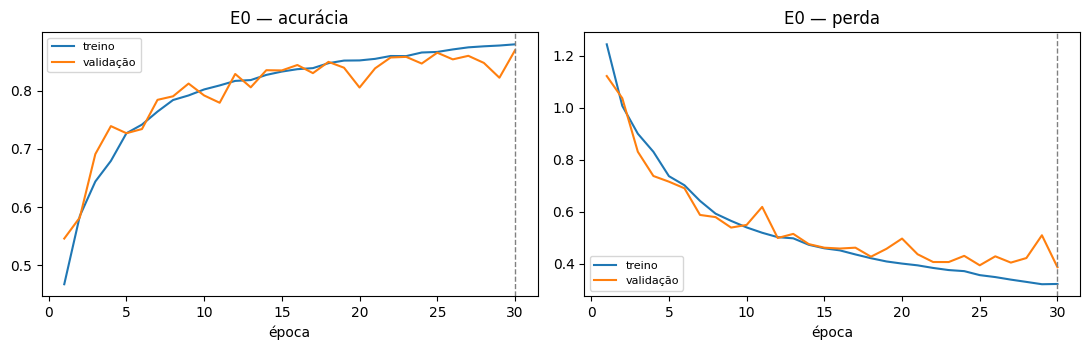

In [16]:
executar_experimento("E0", "Modelo inicial (sem Dropout, L2 ou aumento)", **dict())
mostrar_curvas("E0")

### E1 — Taxa de aprendizado 0,0001
Só a taxa de aprendizado muda (0,001 → 0,0001).


===== E1: Taxa de aprendizado 0,0001 =====
Epoch 1/30
350/350 - 13s - 37ms/step - accuracy: 0.3902 - loss: 1.4828 - val_accuracy: 0.4620 - val_loss: 1.2946
Epoch 2/30
350/350 - 8s - 22ms/step - accuracy: 0.4754 - loss: 1.2507 - val_accuracy: 0.5330 - val_loss: 1.1974
Epoch 3/30
350/350 - 8s - 22ms/step - accuracy: 0.5182 - loss: 1.1795 - val_accuracy: 0.5516 - val_loss: 1.1353
Epoch 4/30
350/350 - 8s - 22ms/step - accuracy: 0.5433 - loss: 1.1225 - val_accuracy: 0.5673 - val_loss: 1.0888
Epoch 5/30
350/350 - 8s - 22ms/step - accuracy: 0.5712 - loss: 1.0697 - val_accuracy: 0.5906 - val_loss: 1.0494
Epoch 6/30
350/350 - 8s - 22ms/step - accuracy: 0.5926 - loss: 1.0266 - val_accuracy: 0.6135 - val_loss: 0.9944
Epoch 7/30
350/350 - 8s - 22ms/step - accuracy: 0.6084 - loss: 0.9947 - val_accuracy: 0.6254 - val_loss: 0.9745
Epoch 8/30
350/350 - 8s - 22ms/step - accuracy: 0.6188 - loss: 0.9729 - val_accuracy: 0.6236 - val_loss: 0.9581
Epoch 9/30
350/350 - 8s - 22ms/step - accuracy: 0.6275 - lo

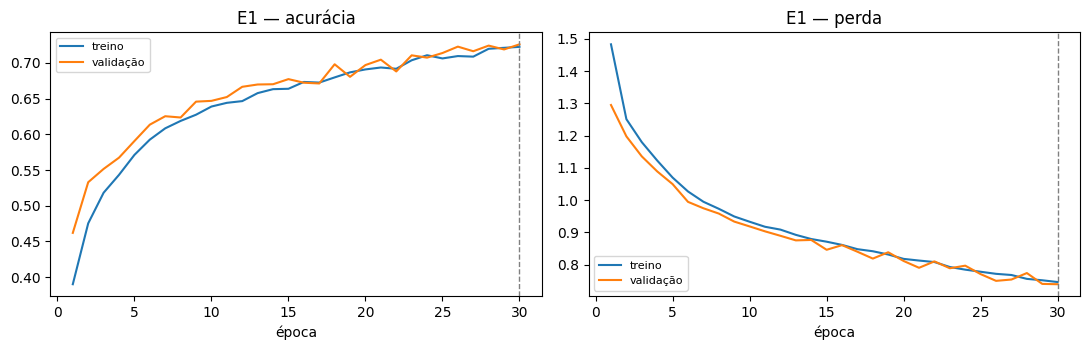

In [17]:
executar_experimento("E1", "Taxa de aprendizado 0,0001", **dict(lr=1e-4))
mostrar_curvas("E1")

### E2 — Capacidade: 4 blocos (32-64-128-256)
Só a capacidade muda: um quarto bloco Conv2D(256)+MaxPooling. Optou-se por aumentar o número de blocos (e não dobrar os filtros) porque aumenta a profundidade/campo receptivo com custo computacional moderado.


===== E2: Capacidade: 4 blocos (32-64-128-256) =====
Epoch 1/30
350/350 - 17s - 49ms/step - accuracy: 0.4945 - loss: 1.1704 - val_accuracy: 0.5663 - val_loss: 1.0649
Epoch 2/30
350/350 - 8s - 24ms/step - accuracy: 0.6618 - loss: 0.8651 - val_accuracy: 0.7099 - val_loss: 0.8055
Epoch 3/30
350/350 - 9s - 24ms/step - accuracy: 0.7388 - loss: 0.7187 - val_accuracy: 0.7661 - val_loss: 0.6447
Epoch 4/30
350/350 - 10s - 29ms/step - accuracy: 0.7720 - loss: 0.6188 - val_accuracy: 0.8016 - val_loss: 0.5450
Epoch 5/30
350/350 - 8s - 24ms/step - accuracy: 0.8019 - loss: 0.5448 - val_accuracy: 0.8277 - val_loss: 0.4792
Epoch 6/30
350/350 - 8s - 24ms/step - accuracy: 0.8123 - loss: 0.5174 - val_accuracy: 0.8256 - val_loss: 0.4855
Epoch 7/30
350/350 - 8s - 24ms/step - accuracy: 0.8279 - loss: 0.4730 - val_accuracy: 0.8234 - val_loss: 0.4965
Epoch 8/30
350/350 - 8s - 24ms/step - accuracy: 0.8359 - loss: 0.4506 - val_accuracy: 0.8532 - val_loss: 0.4365
Epoch 9/30
350/350 - 8s - 23ms/step - accuracy: 

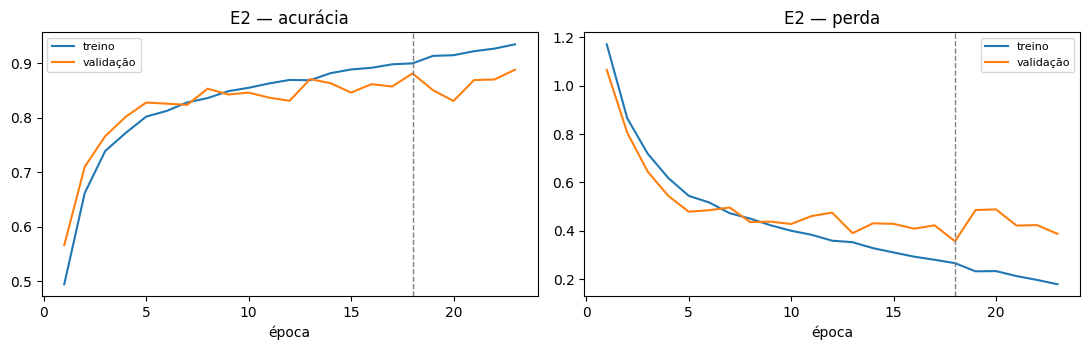

In [18]:
executar_experimento("E2", "Capacidade: 4 blocos (32-64-128-256)", **dict(filtros=(32, 64, 128, 256)))
mostrar_curvas("E2")

### E3 — Dropout 0,3 antes da saída
Dropout 0,3 entre a Dense(128) e a camada de saída.


===== E3: Dropout 0,3 antes da saída =====
Epoch 1/30
350/350 - 14s - 40ms/step - accuracy: 0.4407 - loss: 1.2825 - val_accuracy: 0.5236 - val_loss: 1.1737
Epoch 2/30
350/350 - 8s - 22ms/step - accuracy: 0.5499 - loss: 1.0697 - val_accuracy: 0.5415 - val_loss: 1.1267
Epoch 3/30
350/350 - 8s - 22ms/step - accuracy: 0.6181 - loss: 0.9566 - val_accuracy: 0.6486 - val_loss: 0.9005
Epoch 4/30
350/350 - 8s - 22ms/step - accuracy: 0.6732 - loss: 0.8525 - val_accuracy: 0.7256 - val_loss: 0.7486
Epoch 5/30
350/350 - 8s - 22ms/step - accuracy: 0.7230 - loss: 0.7487 - val_accuracy: 0.7439 - val_loss: 0.7058
Epoch 6/30
350/350 - 8s - 22ms/step - accuracy: 0.7408 - loss: 0.7086 - val_accuracy: 0.7511 - val_loss: 0.6677
Epoch 7/30
350/350 - 8s - 22ms/step - accuracy: 0.7594 - loss: 0.6663 - val_accuracy: 0.7905 - val_loss: 0.5899
Epoch 8/30
350/350 - 8s - 21ms/step - accuracy: 0.7765 - loss: 0.6182 - val_accuracy: 0.7779 - val_loss: 0.6015
Epoch 9/30
350/350 - 8s - 22ms/step - accuracy: 0.7854 - lo

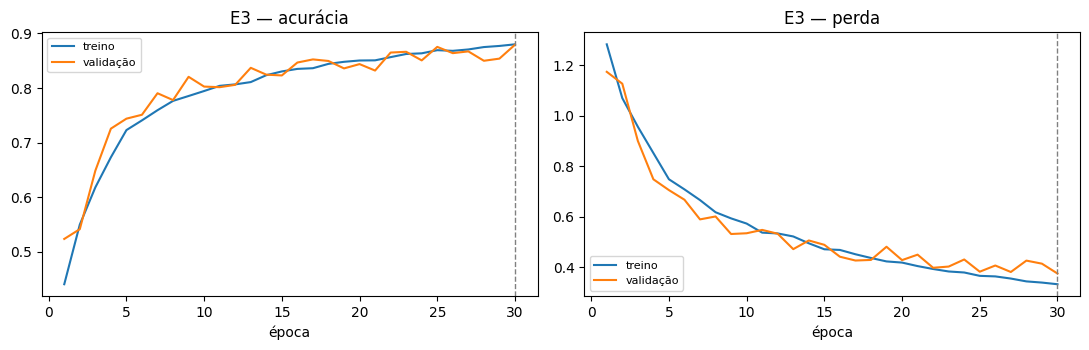

In [19]:
executar_experimento("E3", "Dropout 0,3 antes da saída", **dict(dropout=0.3))
mostrar_curvas("E3")

### E4 — Dropout 0,5 antes da saída
Mesma posição do E3, taxa 0,5.


===== E4: Dropout 0,5 antes da saída =====
Epoch 1/30
350/350 - 14s - 39ms/step - accuracy: 0.4252 - loss: 1.3305 - val_accuracy: 0.5290 - val_loss: 1.1608
Epoch 2/30
350/350 - 8s - 22ms/step - accuracy: 0.5308 - loss: 1.1017 - val_accuracy: 0.5236 - val_loss: 1.1595
Epoch 3/30
350/350 - 8s - 22ms/step - accuracy: 0.5930 - loss: 1.0080 - val_accuracy: 0.6232 - val_loss: 0.9647
Epoch 4/30
350/350 - 8s - 22ms/step - accuracy: 0.6462 - loss: 0.9129 - val_accuracy: 0.7027 - val_loss: 0.7959
Epoch 5/30
350/350 - 8s - 21ms/step - accuracy: 0.6966 - loss: 0.8140 - val_accuracy: 0.7385 - val_loss: 0.7190
Epoch 6/30
350/350 - 7s - 21ms/step - accuracy: 0.7197 - loss: 0.7623 - val_accuracy: 0.6888 - val_loss: 0.7693
Epoch 7/30
350/350 - 8s - 22ms/step - accuracy: 0.7446 - loss: 0.7055 - val_accuracy: 0.7862 - val_loss: 0.6224
Epoch 8/30
350/350 - 7s - 21ms/step - accuracy: 0.7628 - loss: 0.6558 - val_accuracy: 0.8109 - val_loss: 0.5555
Epoch 9/30
350/350 - 8s - 22ms/step - accuracy: 0.7716 - lo

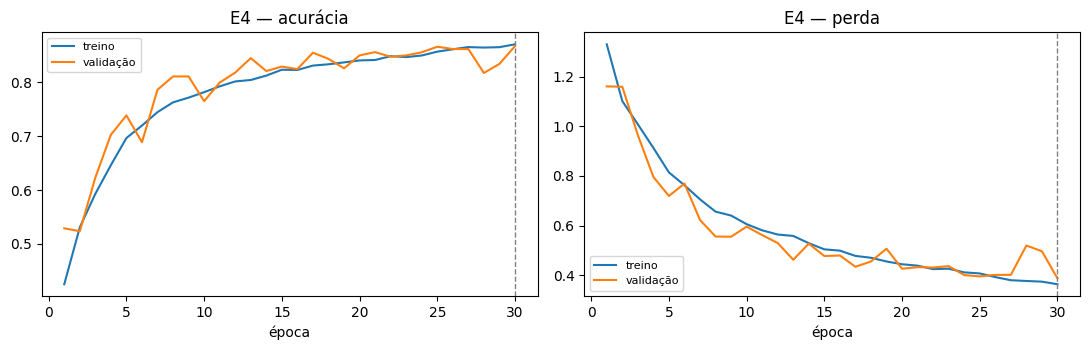

In [20]:
executar_experimento("E4", "Dropout 0,5 antes da saída", **dict(dropout=0.5))
mostrar_curvas("E4")

### E5 — L2 = 0,0001 nas Conv2D e Dense(128)
Penalidade L2 de 0,0001 nos *kernels* das três camadas Conv2D e da Dense(128) oculta (a camada de saída e os *bias* não são regularizados). A perda do Keras deste experimento inclui o termo L2.


===== E5: L2 = 0,0001 nas Conv2D e Dense(128) =====
Epoch 1/30
350/350 - 14s - 40ms/step - accuracy: 0.4587 - loss: 1.2706 - val_accuracy: 0.5322 - val_loss: 1.1694
Epoch 2/30
350/350 - 8s - 21ms/step - accuracy: 0.5734 - loss: 1.0561 - val_accuracy: 0.5498 - val_loss: 1.1427
Epoch 3/30
350/350 - 8s - 21ms/step - accuracy: 0.6311 - loss: 0.9425 - val_accuracy: 0.6494 - val_loss: 0.9096
Epoch 4/30
350/350 - 8s - 22ms/step - accuracy: 0.6547 - loss: 0.8966 - val_accuracy: 0.6981 - val_loss: 0.8314
Epoch 5/30
350/350 - 8s - 22ms/step - accuracy: 0.7009 - loss: 0.8173 - val_accuracy: 0.7213 - val_loss: 0.7973
Epoch 6/30
350/350 - 8s - 22ms/step - accuracy: 0.7182 - loss: 0.7884 - val_accuracy: 0.7328 - val_loss: 0.7628
Epoch 7/30
350/350 - 8s - 21ms/step - accuracy: 0.7370 - loss: 0.7404 - val_accuracy: 0.7747 - val_loss: 0.6745
Epoch 8/30
350/350 - 8s - 21ms/step - accuracy: 0.7607 - loss: 0.6952 - val_accuracy: 0.7285 - val_loss: 0.7481
Epoch 9/30
350/350 - 8s - 22ms/step - accuracy: 0.

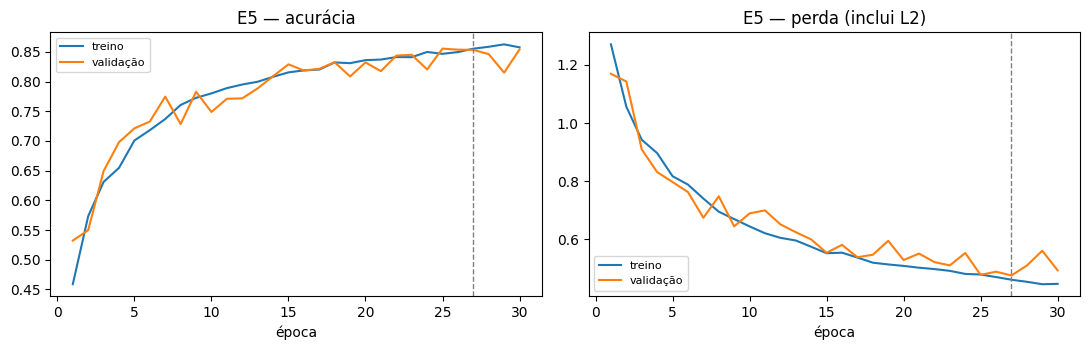

In [21]:
executar_experimento("E5", "L2 = 0,0001 nas Conv2D e Dense(128)", **dict(l2=1e-4))
mostrar_curvas("E5")

### E6 — Aumento de dados (flip horizontal, rotação ±11°, zoom ±10%)
Espelhamento horizontal, rotação de até ±0,03 volta (~±11°) e zoom de até ±10%, só no treino. Não se usou espelhamento vertical porque céu/chão invertidos não ocorrem nas cenas reais.


===== E6: Aumento de dados (flip horizontal, rotação ±11°, zoom ±10%) =====
Epoch 1/30
350/350 - 36s - 102ms/step - accuracy: 0.4649 - loss: 1.2544 - val_accuracy: 0.3771 - val_loss: 1.7474
Epoch 2/30
350/350 - 31s - 87ms/step - accuracy: 0.5641 - loss: 1.0570 - val_accuracy: 0.5244 - val_loss: 1.2576
Epoch 3/30
350/350 - 31s - 88ms/step - accuracy: 0.6032 - loss: 0.9792 - val_accuracy: 0.5663 - val_loss: 1.1159
Epoch 4/30
350/350 - 31s - 88ms/step - accuracy: 0.6407 - loss: 0.9100 - val_accuracy: 0.6458 - val_loss: 0.9510
Epoch 5/30
350/350 - 41s - 117ms/step - accuracy: 0.6852 - loss: 0.8351 - val_accuracy: 0.7135 - val_loss: 0.7752
Epoch 6/30
350/350 - 31s - 88ms/step - accuracy: 0.7121 - loss: 0.7714 - val_accuracy: 0.6669 - val_loss: 0.8332
Epoch 7/30
350/350 - 31s - 88ms/step - accuracy: 0.7342 - loss: 0.7184 - val_accuracy: 0.7794 - val_loss: 0.6080
Epoch 8/30
350/350 - 31s - 88ms/step - accuracy: 0.7602 - loss: 0.6497 - val_accuracy: 0.7038 - val_loss: 0.7493
Epoch 9/30
350/35

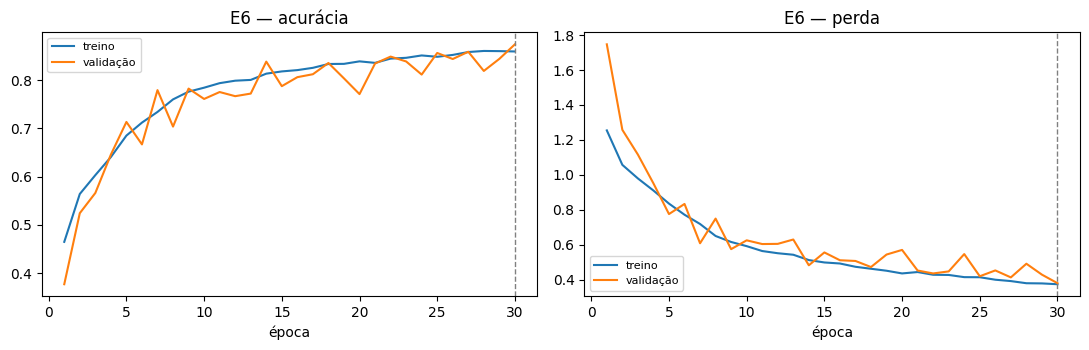

In [22]:
executar_experimento("E6", "Aumento de dados (flip horizontal, rotação ±11°, zoom ±10%)", **dict(aumentar=True))
mostrar_curvas("E6")

### E7 — Modelo final (combinação definida pela validação)

A regra de combinação foi fixada **antes** de ver os resultados e usa apenas o F1 macro de **validação**:
cada alteração de E1–E6 entra no E7 se tiver superado o E0. Para o Dropout, usa-se a melhor taxa entre E3 e E4
(se alguma superou o E0). Caso menos de duas alterações tenham superado o E0, combinam-se as duas de maior F1 de
validação, para que E7 seja de fato uma combinação.

In [23]:
f1 = {k: v["f1_macro_val"] for k, v in resultados.items()}
base = f1["E0"]
candidatos = {  # experimento -> alteração correspondente
    "E1": dict(lr=1e-4), "E2": dict(filtros=(32, 64, 128, 256)),
    "E3": dict(dropout=0.3), "E4": dict(dropout=0.5), "E5": dict(l2=1e-4), "E6": dict(aumentar=True),
}
melhor_dropout = max(["E3", "E4"], key=lambda k: f1[k])
ordem = sorted([k for k in candidatos if k not in ("E3", "E4")] + [melhor_dropout], key=lambda k: -f1[k])
escolhidos = [k for k in ordem if f1[k] > base]
if len(escolhidos) < 2:
    escolhidos = ordem[:2]

config_e7 = {}
for k in escolhidos:
    config_e7.update(candidatos[k])
print("F1 macro de validação:", {k: round(v, 4) for k, v in f1.items()})
print("Alterações escolhidas para o E7:", escolhidos, "->", config_e7)
desc_e7 = "Combinação: " + ", ".join(f"{k} ({resultados[k]['descricao']})" for k in escolhidos)

F1 macro de validação: {'E0': 0.8695, 'E1': 0.7289, 'E2': 0.8822, 'E3': 0.8804, 'E4': 0.8676, 'E5': 0.8538, 'E6': 0.8747}
Alterações escolhidas para o E7: ['E2', 'E3', 'E6'] -> {'filtros': (32, 64, 128, 256), 'dropout': 0.3, 'aumentar': True}



===== E7: Combinação: E2 (Capacidade: 4 blocos (32-64-128-256)), E3 (Dropout 0,3 antes da saída), E6 (Aumento de dados (flip horizontal, rotação ±11°, zoom ±10%)) =====
Epoch 1/30
350/350 - 38s - 108ms/step - accuracy: 0.4516 - loss: 1.2508 - val_accuracy: 0.4713 - val_loss: 1.4907
Epoch 2/30
350/350 - 31s - 87ms/step - accuracy: 0.6098 - loss: 0.9873 - val_accuracy: 0.6254 - val_loss: 0.9651
Epoch 3/30
350/350 - 31s - 88ms/step - accuracy: 0.6894 - loss: 0.8336 - val_accuracy: 0.7367 - val_loss: 0.7203
Epoch 4/30
350/350 - 31s - 88ms/step - accuracy: 0.7385 - loss: 0.7155 - val_accuracy: 0.7604 - val_loss: 0.6846
Epoch 5/30
350/350 - 31s - 89ms/step - accuracy: 0.7681 - loss: 0.6376 - val_accuracy: 0.8170 - val_loss: 0.5362
Epoch 6/30
350/350 - 40s - 116ms/step - accuracy: 0.7843 - loss: 0.6040 - val_accuracy: 0.7987 - val_loss: 0.5544
Epoch 7/30
350/350 - 31s - 88ms/step - accuracy: 0.7962 - loss: 0.5680 - val_accuracy: 0.7923 - val_loss: 0.5600
Epoch 8/30
350/350 - 31s - 87ms/step 

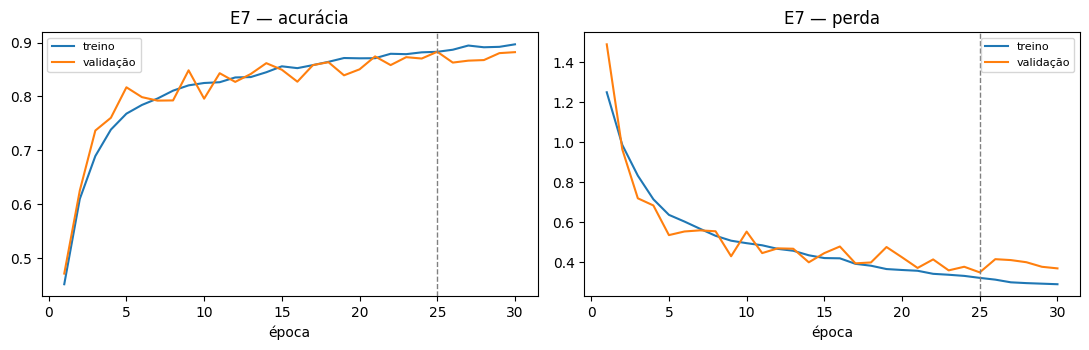

In [24]:
executar_experimento("E7", desc_e7, **config_e7)
mostrar_curvas("E7")

## 9. Comparação dos experimentos (validação)

In [25]:
tab = pd.DataFrame(resultados.values()).set_index("id")
tab.to_csv(PASTA_SAIDA / "resultados_experimentos.csv")
cols = ["descricao", "parametros_treinaveis", "epocas_executadas", "melhor_epoca", "tempo_treino_s",
        "acc_treino", "acc_val", "perda_ce_treino", "perda_ce_val", "perda_total_val", "f1_macro_val"]
tab[cols].style.format({c: "{:.4f}" for c in cols if c.startswith(("acc", "perda", "f1"))})

,descricao,parametros_treinaveis,epocas_executadas,melhor_epoca,tempo_treino_s,acc_treino,acc_val,perda_ce_treino,perda_ce_val,perda_total_val,f1_macro_val
id,,,,,,,,,,,
E0,"Modelo inicial (sem Dropout, L2 ou aumento)",110534,30,30,243.900000,0.8905,0.8689,0.2881,0.3861,0.3861,0.8695
E1,"Taxa de aprendizado 0,0001",110534,30,30,238.300000,0.7293,0.7260,0.7478,0.7390,0.7390,0.7289
E2,Capacidade: 4 blocos (32-64-128-256),422086,23,18,203.000000,0.9299,0.8811,0.1979,0.3571,0.3571,0.8822
E3,"Dropout 0,3 antes da saída",110534,30,30,235.400000,0.8970,0.8793,0.2814,0.3757,0.3757,0.8804
E4,"Dropout 0,5 antes da saída",110534,30,30,235.400000,0.8927,0.8671,0.2963,0.3870,0.3870,0.8676
E5,"L2 = 0,0001 nas Conv2D e Dense(128)",110534,30,27,234.900000,0.8700,0.8535,0.3626,0.4096,0.4760,0.8538
E6,"Aumento de dados (flip horizontal, rotação ±11°, zoom ±10%)",110534,30,30,954.500000,0.8784,0.8743,0.3267,0.3794,0.3794,0.8747
E7,"Combinação: E2 (Capacidade: 4 blocos (32-64-128-256)), E3 (Dropout 0,3 antes da saída), E6 (Aumento de dados (flip horizontal, rotação ±11°, zoom ±10%))",422086,30,25,1005.600000,0.9040,0.8829,0.2612,0.3498,0.3498,0.8835


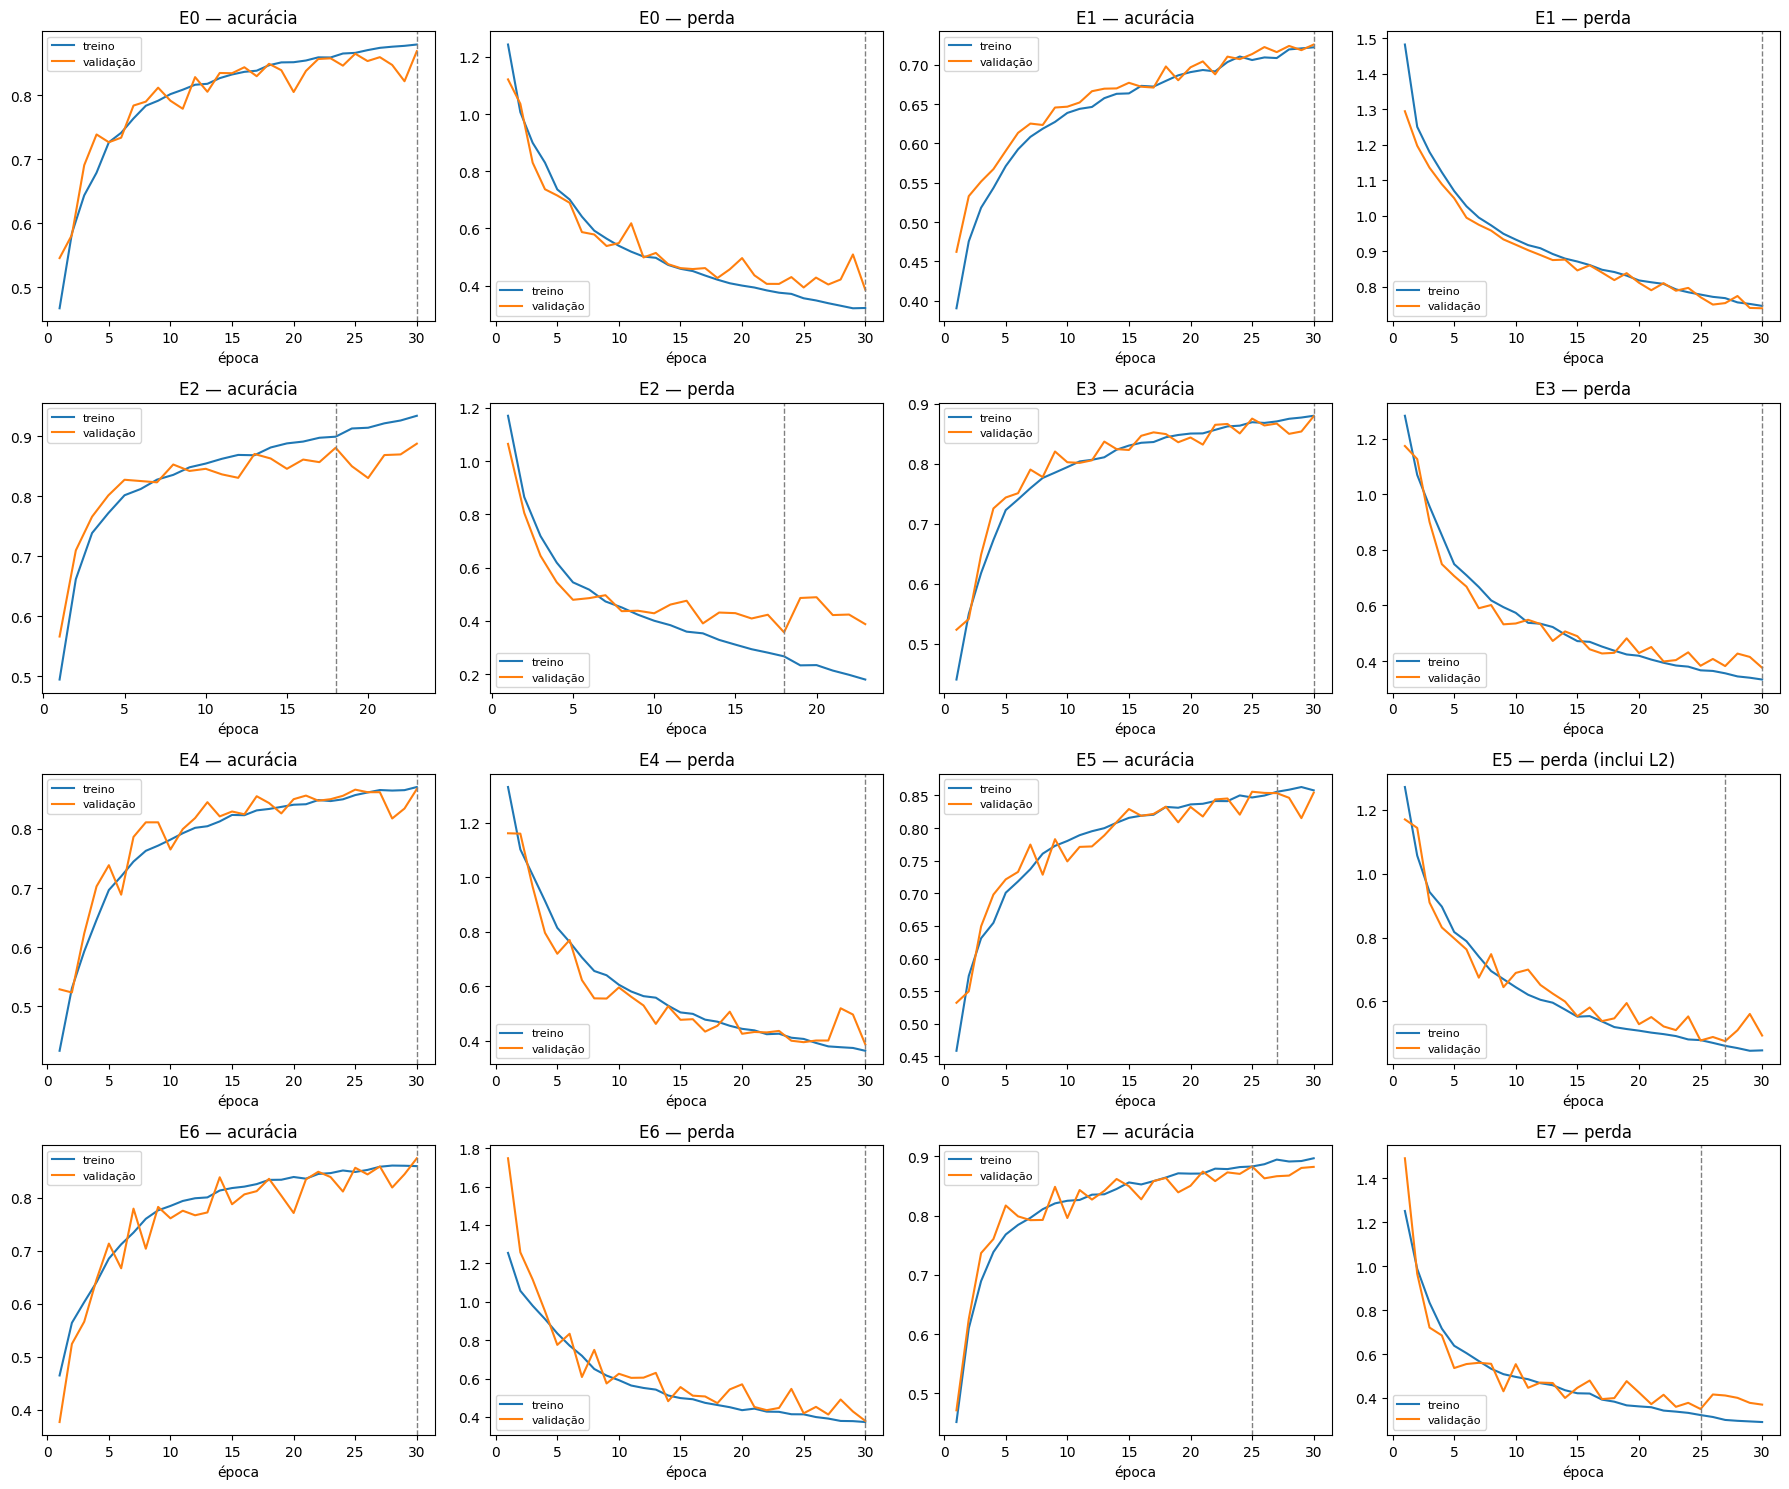

In [26]:
fig, eixos = plt.subplots(4, 4, figsize=(18, 15))
for k, id_exp in enumerate(resultados):
    plotar_curvas(id_exp, eixos.flat[2 * k], eixos.flat[2 * k + 1])
plt.tight_layout(); plt.savefig(PASTA_FIG / "curvas_todos.png", dpi=90); plt.show()

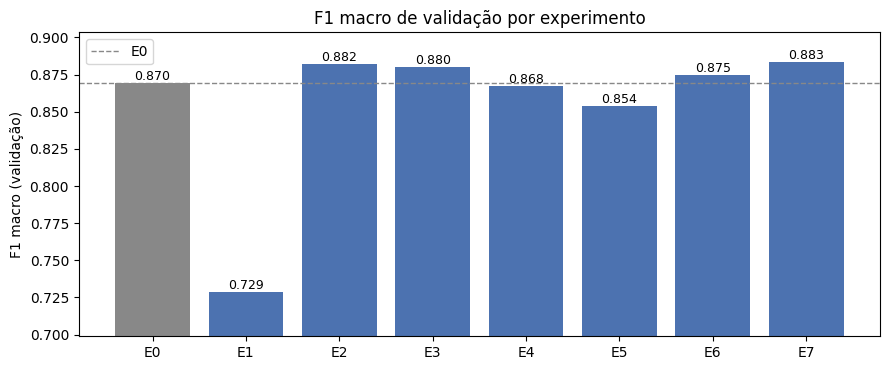

In [27]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ids = list(tab.index)
ax.bar(ids, tab["f1_macro_val"], color=["#4C72B0" if i != "E0" else "#888" for i in ids])
ax.axhline(tab.loc["E0", "f1_macro_val"], color="#888", ls="--", lw=1, label="E0")
for i, v in enumerate(tab["f1_macro_val"]):
    ax.text(i, v + 0.002, f"{v:.3f}", ha="center", fontsize=9)
lo = tab["f1_macro_val"].min() - 0.03
ax.set_ylim(lo, min(1, tab["f1_macro_val"].max() + 0.02)); ax.set_ylabel("F1 macro (validação)")
ax.set_title("F1 macro de validação por experimento"); ax.legend()
plt.tight_layout(); plt.savefig(PASTA_FIG / "f1_validacao.png", dpi=110); plt.show()

## 10. Seleção do modelo

Critério: **maior F1 macro de validação**; em empate (diferença < 0,001), menor número de parâmetros.

In [28]:
ordenado = tab.sort_values(["f1_macro_val", "parametros_treinaveis"], ascending=[False, True])
topo = ordenado.iloc[0]
empatados = ordenado[(topo["f1_macro_val"] - ordenado["f1_macro_val"]) < 0.001]
selecionado = empatados.sort_values("parametros_treinaveis").index[0]
print("Ranking por F1 macro de validação:")
print(ordenado[["f1_macro_val", "acc_val", "parametros_treinaveis"]].to_string())
print("\nModelo selecionado:", selecionado, "-", tab.loc[selecionado, "descricao"])
print("Checkpoint:", tab.loc[selecionado, "checkpoint"])

Ranking por F1 macro de validação:
    f1_macro_val   acc_val  parametros_treinaveis
id                                               
E7      0.883468  0.882880                 422086
E2      0.882151  0.881089                 422086
E3      0.880444  0.879298                 110534
E6      0.874681  0.874284                 110534
E0      0.869505  0.868911                 110534
E4      0.867592  0.867120                 110534
E5      0.853826  0.853510                 110534
E1      0.728870  0.726003                 110534

Modelo selecionado: E7 - Combinação: E2 (Capacidade: 4 blocos (32-64-128-256)), E3 (Dropout 0,3 antes da saída), E6 (Aumento de dados (flip horizontal, rotação ±11°, zoom ±10%))
Checkpoint: resultados/modelos/E7.weights.h5


## 11. Avaliação final no teste

Os ajustes foram encerrados. O modelo selecionado é reconstruído, carregado do seu checkpoint e avaliado **uma
única vez** no teste oficial. Nenhum ajuste é feito com base nestes números.

In [29]:
cfg = tab.loc[selecionado]
filtros_sel = (32, 64, 128, 256) if "4 blocos" in cfg["arquitetura"] else (32, 64, 128)
keras.backend.clear_session()
modelo_final = construir_cnn(filtros=filtros_sel, dropout=float(cfg["dropout"]), l2=float(cfg["l2"]), nome=selecionado)
modelo_final.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
modelo_final.load_weights(cfg["checkpoint"])

prob_te = modelo_final.predict(ds_te, verbose=0)
pred_te = prob_te.argmax(1)
acc_te = accuracy_score(y_te, pred_te)
f1_te = f1_score(y_te, pred_te, average="macro")
print(f"Teste — acurácia: {acc_te:.4f} | F1 macro: {f1_te:.4f}\n")
print(classification_report(y_te, pred_te, target_names=classes, digits=4))

p, r, f, s = precision_recall_fscore_support(y_te, pred_te)
metricas_teste = pd.DataFrame({"precisao": p, "recall": r, "f1": f, "suporte": s}, index=classes)
metricas_teste.loc["macro"] = [p.mean(), r.mean(), f.mean(), s.sum()]
metricas_teste.loc["acuracia"] = [acc_te, acc_te, acc_te, s.sum()]
metricas_teste.to_csv(PASTA_SAIDA / "metricas_teste.csv")

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 26 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Teste — acurácia: 0.8737 | F1 macro: 0.8748

              precision    recall  f1-score   support

   buildings     0.8132    0.8764    0.8436       437
      forest     0.9848    0.9557    0.9700       474
     glacier     0.8367    0.8336    0.8351       553
    mountain     0.8583    0.7848    0.8199       525
         sea     0.8800    0.9059    0.8928       510
      street     0.8772    0.8982    0.8876       501

    accuracy                         0.8737      3000
   macro avg     0.8750    0.8758    0.8748      3000
weighted avg     0.8746    0.8737    0.8736      3000



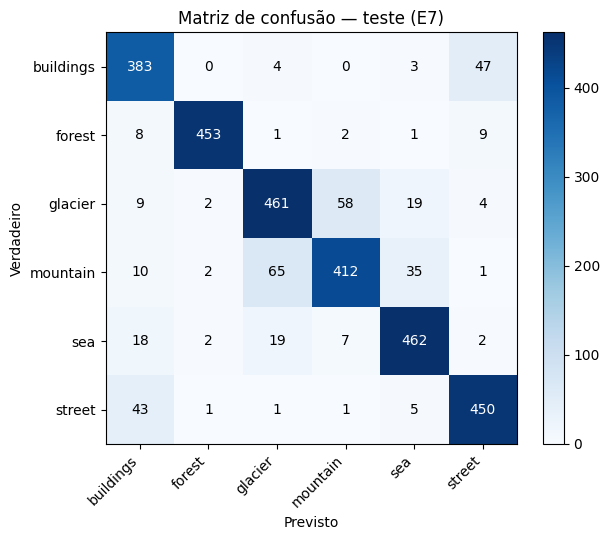

Confusões mais frequentes (verdadeiro -> previsto):
  mountain  -> glacier  : 65
  glacier   -> mountain : 58
  buildings -> street   : 47
  street    -> buildings: 43
  mountain  -> sea      : 35
  glacier   -> sea      : 19


In [30]:
cm = confusion_matrix(y_te, pred_te)
pd.DataFrame(cm, index=classes, columns=classes).to_csv(PASTA_SAIDA / "matriz_confusao_teste.csv")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(6), classes, rotation=45, ha="right"); ax.set_yticks(range(6), classes)
for i in range(6):
    for j in range(6):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("Previsto"); ax.set_ylabel("Verdadeiro"); ax.set_title(f"Matriz de confusão — teste ({selecionado})")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.savefig(PASTA_FIG / "matriz_confusao.png", dpi=120); plt.show()

pares = [(classes[i], classes[j], cm[i, j]) for i in range(6) for j in range(6) if i != j]
print("Confusões mais frequentes (verdadeiro -> previsto):")
for a, b, c in sorted(pares, key=lambda t: -t[2])[:6]:
    print(f"  {a:9s} -> {b:9s}: {c}")

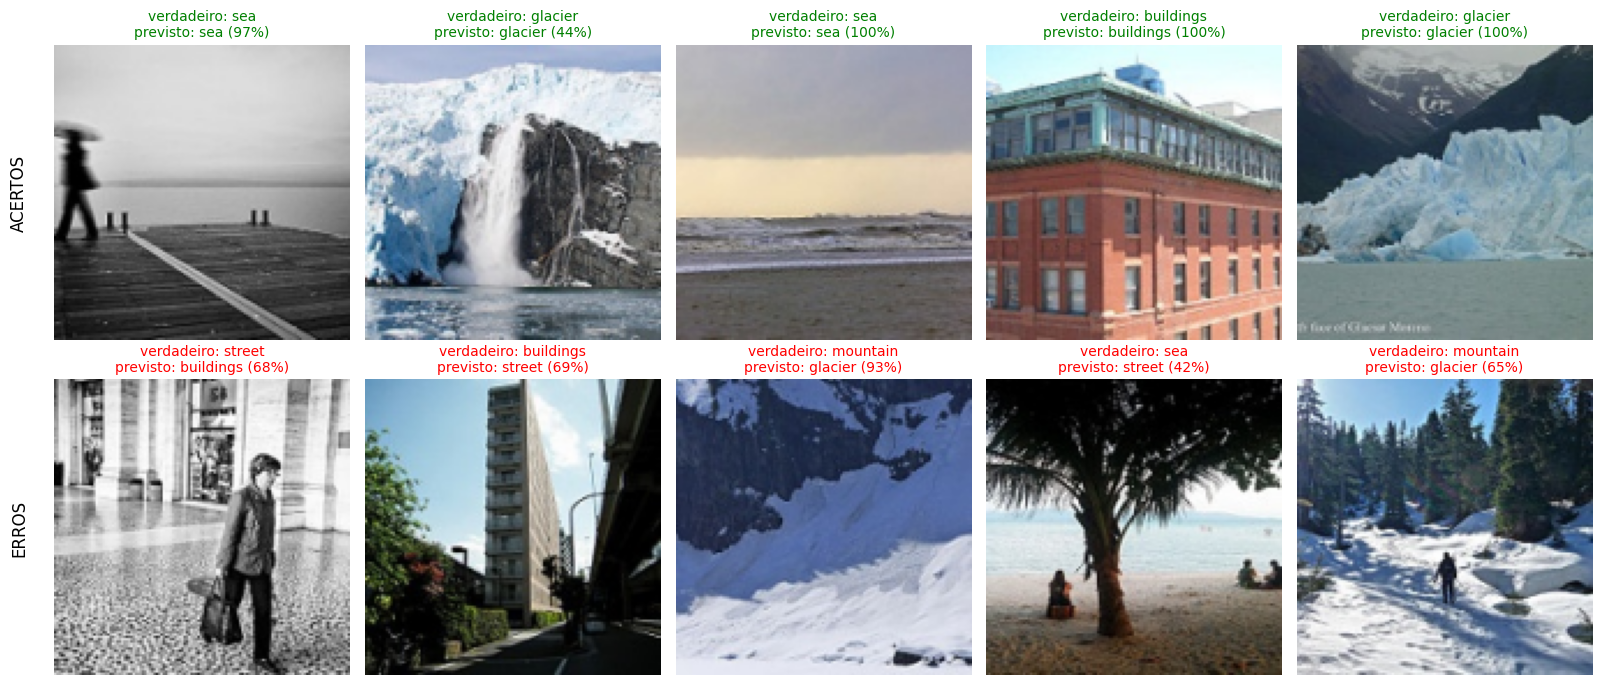

In [31]:
rng = np.random.default_rng(SEED)
acertos = np.flatnonzero(pred_te == y_te)
erros = np.flatnonzero(pred_te != y_te)
sel_ok = rng.choice(acertos, min(5, len(acertos)), replace=False)
sel_err = rng.choice(erros, min(5, len(erros)), replace=False)
fig, eixos = plt.subplots(2, 5, figsize=(16, 7))
for linha, idxs, cor in ((0, sel_ok, "green"), (1, sel_err, "red")):
    for k, i in enumerate(idxs):
        ax = eixos[linha, k]; ax.imshow(X_te[i]); ax.axis("off")
        ax.set_title(f"verdadeiro: {classes[y_te[i]]}\nprevisto: {classes[pred_te[i]]} ({prob_te[i].max():.0%})",
                     color=cor, fontsize=10)
eixos[0, 0].text(-0.15, 0.5, "ACERTOS", transform=eixos[0, 0].transAxes, rotation=90, va="center", fontsize=12)
eixos[1, 0].text(-0.15, 0.5, "ERROS", transform=eixos[1, 0].transAxes, rotation=90, va="center", fontsize=12)
plt.tight_layout(); plt.savefig(PASTA_FIG / "acertos_erros.png", dpi=100); plt.show()

In [32]:
# Resumo final salvo em JSON (usado no relatório)
resumo = {"selecionado": selecionado, "acc_teste": acc_te, "f1_macro_teste": f1_te,
          "escolhidos_e7": escolhidos, "config_e7": {k: (list(v) if isinstance(v, tuple) else v) for k, v in config_e7.items()}}
json.dump(resumo, open(PASTA_SAIDA / "resumo_final.json", "w"), indent=2, ensure_ascii=False)
resumo

{'selecionado': 'E7',
 'acc_teste': 0.8736666666666667,
 'f1_macro_teste': 0.8748344601353516,
 'escolhidos_e7': ['E2', 'E3', 'E6'],
 'config_e7': {'filtros': [32, 64, 128, 256],
  'dropout': 0.3,
  'aumentar': True}}

In [33]:
!zip -r resultados.zip resultados

  adding: resultados/ (stored 0%)
  adding: resultados/modelos/ (stored 0%)
  adding: resultados/modelos/E4.weights.h5 (deflated 11%)
  adding: resultados/modelos/E7.weights.h5 (deflated 11%)
  adding: resultados/modelos/E1.weights.h5 (deflated 11%)
  adding: resultados/modelos/E2.weights.h5 (deflated 11%)
  adding: resultados/modelos/E5.weights.h5 (deflated 10%)
  adding: resultados/modelos/E6.weights.h5 (deflated 11%)
  adding: resultados/modelos/E0.weights.h5 (deflated 11%)
  adding: resultados/modelos/E3.weights.h5 (deflated 11%)
  adding: resultados/distribuicao_classes.csv (deflated 27%)
  adding: resultados/exclusoes.csv (deflated 90%)
  adding: resultados/resumo_final.json (deflated 41%)
  adding: resultados/split_validacao.csv (deflated 85%)
  adding: resultados/figuras/ (stored 0%)
  adding: resultados/figuras/curvas_todos.png (deflated 4%)
  adding: resultados/figuras/exemplos_classes.png (deflated 0%)
  adding: resultados/figuras/acertos_erros.png (deflated 0%)
  adding: re

## 12. Discussão dos resultados

| ID | Alteração | Parâm. | Épocas (melhor) | Acc val | F1 macro val |
|---|---|---|---|---|---|
| E0 | modelo inicial | 110.534 | 30 (30) | 0,869 | 0,8695 |
| E1 | lr 0,0001 | 110.534 | 30 (30) | 0,726 | 0,7289 |
| E2 | 4 blocos | 422.086 | 23 (18) | 0,881 | 0,8822 |
| E3 | Dropout 0,3 | 110.534 | 30 (30) | 0,879 | 0,8804 |
| E4 | Dropout 0,5 | 110.534 | 30 (30) | 0,867 | 0,8676 |
| E5 | L2 0,0001 | 110.534 | 30 (27) | 0,854 | 0,8538 |
| E6 | aumento de dados | 110.534 | 30 (30) | 0,874 | 0,8747 |
| **E7** | **E2 + E3 + E6** | 422.086 | 30 (25) | **0,883** | **0,8835** |

**O modelo inicial apresentou overfitting ou underfitting?** Não houve overfitting: as curvas de treino e validação
andaram juntas (acurácia 0,890 × 0,869 no checkpoint) e a menor perda de validação ocorreu na 30ª e última época.
O modelo ficou levemente **subtreinado** (underfitting por falta de épocas): a melhor época foi a última.

**Taxa de aprendizado e capacidade.** Com lr = 0,0001 (E1) a convergência foi muito lenta — 0,73 de acurácia após 30 épocas,
underfitting claro. O quarto bloco (E2) acelerou a convergência (melhor época 18) e deu o melhor resultado isolado, mas a partir
daí a perda de treino continuou caindo enquanto a de validação subiu (0,357 → 0,388): início de **overfitting**, interrompido
pelo EarlyStopping na época 23.

**Regularização.** Dropout 0,3 foi a técnica de regularização de maior ganho (+0,011 de F1); o aumento de dados ajudou um pouco
(+0,005) e, nas curvas (medidas com aumento ativo), manteve a validação acima do treino, a um custo de ~4× o tempo. Com uma
única semente, diferenças dessa ordem (~30 imagens de validação) são indícios, não diferenças garantidas. L2 (−0,016) e Dropout 0,5 (−0,002) pioraram: o modelo base não
sobreajustava, então restringi-lo mais apenas reduziu sua capacidade de aprender em 30 épocas. No E5 a perda do Keras inclui o
termo L2 (perda total de validação 0,476 contra 0,410 de entropia cruzada pura), e o EarlyStopping do E5 monitorou essa perda total.

**Classes mais confundidas.** mountain ↔ glacier (65 + 58 erros) e buildings ↔ street (47 + 43), além de mountain → sea (35).
Montanhas nevadas e geleiras dividem cores e relevo; ruas contêm prédios e vice-versa; montanhas com lago/horizonte azul lembram
o mar. *Forest* foi a classe mais fácil (F1 0,970).

**A configuração mais complexa foi a melhor?** Por margem mínima: o E7 teve o maior F1 de validação (0,8835) e, no teste, acurácia 0,8737 e
F1 macro 0,8748. Porém superou o E2 por só 0,0013, com os mesmos 422 mil parâmetros (3,8× o E0) e ~5× o tempo de treino
(1006 s × 203 s), custo vindo sobretudo do aumento de dados executado na CPU.

**Limitações e próximo experimento.** Uma única semente (diferenças de ~0,01 podem ser ruído), teto de 30 épocas que parou
modelos ainda melhorando e rótulos ruidosos na base. Próximo passo: repetir E0/E2/E7 com 3–5 sementes e até 60 épocas, testar
BatchNormalization e agendamento da taxa de aprendizado e, como comparação extra, transferência de aprendizado.